## Import Libraries

In [1]:
import pandas as pd
from math import sin, cos, pi
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

## Data preparation

In [5]:
# Read the Excel file into a DataFrame - data from SQL query
df_sql = pd.read_excel("C:/Users/9000639/Documents/CQ_SerieTemporal/temporal-series-analysis/data/SQL_data.xlsx")
for column in ["ger200k_data_contagem", "ger400k_data_contagem", "ea_data1_contagem", "ger_v_data_contagem"]:
    df_sql[column] = pd.to_datetime(df_sql[column], errors='coerce', dayfirst=True)
df_sql.head()

C:\Users\9000639\AppData\Local\Temp\ipykernel_32320\1466779563.py:4: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df_sql[column] = pd.to_datetime(df_sql[column], errors='coerce', dayfirst=True)
C:\Users\9000639\AppData\Local\Temp\ipykernel_32320\1466779563.py:4: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df_sql[column] = pd.to_datetime(df_sql[column], errors='coerce', dayfirst=True)


,sample_category,sample_type,ger200k_data_contagem,ger400k_data_contagem,ea_data1_contagem,ger_v_data_contagem
0,Comercial,Reanálise de Sobra,NaT,2025-03-26 15:00:00,2025-02-04 15:59:08,NaT
1,Básica,Final Gen2,NaT,NaT,NaT,NaT
2,Comercial,Bulk,NaT,NaT,NaT,NaT
3,Comercial,Bulk Peneiras,2025-03-20 15:00:00,NaT,NaT,NaT
4,Comercial,Bulk Peneiras,2025-03-20 15:00:00,NaT,NaT,NaT


In [9]:
# Read the Excel file into a DataFrame - data from paper sample
df_paper = pd.read_excel("C:/Users/9000639/Documents/CQ_SerieTemporal/temporal-series-analysis/data/Quantidade_papel_amostra.xlsx")
df_paper.head()

,sample_category,sample_type,paper_value
0,Comercial,Reanálise de Sobra,24
1,Comercial,Lote Final,24
2,Comercial,Bulk Peneiras,12
3,Comercial,Devolução,24
4,Comercial,Bulk,12


In [12]:
# Merge the two DataFrames
df = df_sql.merge(df_paper, how='left', on=['sample_category', 'sample_type'], validate='m:1')
df

,sample_category,sample_type,ger200k_data_contagem,ger400k_data_contagem,ea_data1_contagem,ger_v_data_contagem,paper_value
0,Comercial,Reanálise de Sobra,NaT,2025-03-26 15:00:00,2025-02-04 15:59:08,NaT,24.0
1,Básica,Final Gen2,NaT,NaT,NaT,NaT,12.0
2,Comercial,Bulk,NaT,NaT,NaT,NaT,12.0
3,Comercial,Bulk Peneiras,2025-03-20 15:00:00,NaT,NaT,NaT,12.0
4,Comercial,Bulk Peneiras,2025-03-20 15:00:00,NaT,NaT,NaT,12.0
...,...,...,...,...,...,...,...
196015,Comercial,Reanálise de Sobra,NaT,2024-08-27 15:00:00,2024-10-07 14:11:26,NaT,24.0
196016,Comercial,Reanálise de Sobra,NaT,2024-10-02 15:00:00,2024-10-07 14:15:45,NaT,24.0
196017,Comercial,Reanálise de Sobra,NaT,2024-10-02 15:00:00,2024-10-07 14:20:09,NaT,24.0
196018,Comercial,Reanálise de Sobra,NaT,2024-10-02 15:00:00,2024-10-07 14:23:30,NaT,24.0


In [13]:
df_date = df.melt(id_vars=['sample_category', 'sample_type', 'paper_value'],
                  value_vars=['ger200k_data_contagem', 'ger400k_data_contagem', 'ea_data1_contagem', 'ger_v_data_contagem'],
                  var_name='data_type', value_name='date')
df_date = df_date.dropna(subset=['date'])
df_date['date'] = df_date['date'].dt.normalize()  # Normalize the date to remove time component
df_date.head()

,sample_category,sample_type,paper_value,data_type,date
3,Comercial,Bulk Peneiras,12.0,ger200k_data_contagem,2025-03-20
4,Comercial,Bulk Peneiras,12.0,ger200k_data_contagem,2025-03-20
8,Comercial,Bulk Peneiras,12.0,ger200k_data_contagem,2025-03-20
16,Comercial,Bulk Peneiras,12.0,ger200k_data_contagem,2025-03-20
20,Comercial,Bulk Peneiras,12.0,ger200k_data_contagem,2025-03-20


In [14]:
df = (
    df_date.groupby("date", as_index=False)["paper_value"].sum()
    .rename(columns={"paper_value": "daily_paper"})
    .sort_values("date")
    .reset_index(drop=True)
)
df

,date,daily_paper
0,2022-01-06,204.0
1,2022-01-08,1488.0
2,2022-01-09,1512.0
3,2022-01-10,348.0
4,2022-02-05,216.0
...,...,...
1287,2026-12-03,288.0
1288,2026-12-05,216.0
1289,2026-12-06,2256.0
1290,2026-12-08,3996.0


## Data analysis

In [15]:
# Data correlation analysis
# ADF Test
adf_result = adfuller(df["daily_paper"].dropna())
p_value = adf_result[1]
print(f"Estatística ADF: {adf_result[0]:.4f}")
print(f"p-valor: {p_value:.6f}")

Estatística ADF: -5.6026
p-valor: 0.000001


C:\Users\9000639\AppData\Local\Temp\ipykernel_32320\655509601.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df["daily_paper"].dropna())


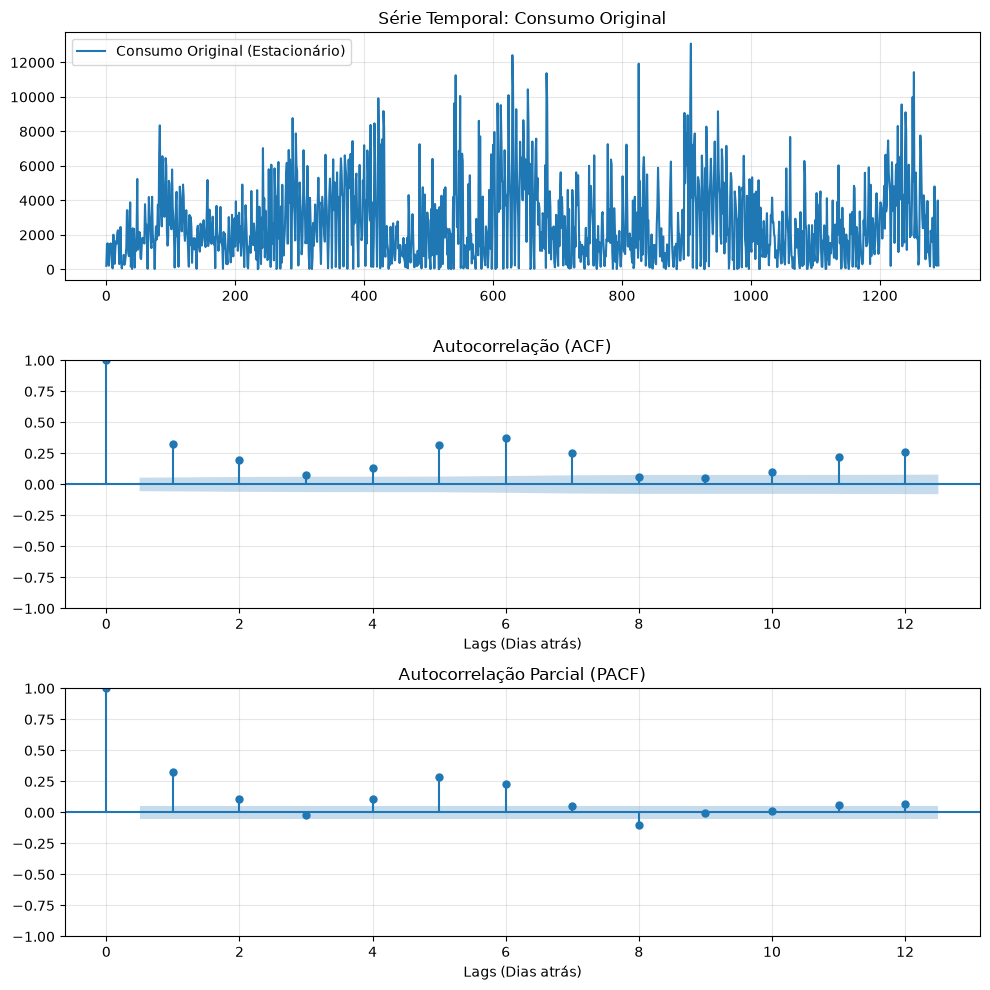

In [19]:
# Visualization of the original and differenced series, along with ACF and PACF plots
fig, axes = plt.subplots(3, 1, figsize=(10, 10))

# Consumption vs Diff
axes[0].plot(df['daily_paper'], label='Consumo Original (Estacionário)', color='tab:blue')
axes[0].set_title('Série Temporal: Consumo Original', fontsize=12)
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

# ACF of Differenced Series
plot_acf(df['daily_paper'].dropna(), ax=axes[1], lags=12, alpha=0.05)
axes[1].set_title('Autocorrelação (ACF)', fontsize=12)
axes[1].set_xlabel('Lags (Dias atrás)')
axes[1].grid(True, alpha=0.3)

# PACF of Differenced Series
plot_pacf(df['daily_paper'].dropna(), ax=axes[2], lags=12, alpha=0.05, method='ywm')
axes[2].set_title('Autocorrelação Parcial (PACF)', fontsize=12)
axes[2].set_xlabel('Lags (Dias atrás)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
# Create new features based on the month and lagged values of the consumption
df["lag1"] = df["daily_paper"].shift(1)
df["lag2"] = df["daily_paper"].shift(2)
df["lag5"] = df["daily_paper"].shift(5)
df["lag6"] = df["daily_paper"].shift(6)
df["lag7"] = df["daily_paper"].shift(7)
df["rolling_mean_3"] = df["daily_paper"].shift(1).rolling(window=3).mean()
df["rolling_mean_7"] = df["daily_paper"].shift(1).rolling(window=7).mean()
df["rolling_mean_14"] = df["daily_paper"].shift(1).rolling(window=14).mean()
df["std_7"] = df["daily_paper"].shift(1).rolling(window=7).std()
df["day_of_week"] = df['date'].dt.dayofweek
df["day_of_month"] = df['date'].dt.day
df["month"] = df['date'].dt.month
df["year"] = df['date'].dt.year
df["week_of_year"] = df['date'].dt.isocalendar().week.astype(int)
df["is_weekend"] = (df['date'].dt.dayofweek >= 5).astype(int)
df["diff_1_7"] = df["lag1"] - df["lag7"]
df["ratio_7_14"] = df["rolling_mean_7"] / df["rolling_mean_14"]
df

,date,daily_paper,lag1,lag2,lag5,lag6,lag7,rolling_mean_3,rolling_mean_7,rolling_mean_14,std_7,day_of_week,day_of_month,month,week_of_year,is_weekend,diff_1_7,ratio_7_14,year
0,2022-01-06,204.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,6,1,1,0,NaN,NaN,2022
1,2022-01-08,1488.0,204.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,8,1,1,1,NaN,NaN,2022
2,2022-01-09,1512.0,1488.0,204.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6,9,1,1,1,NaN,NaN,2022
3,2022-01-10,348.0,1512.0,1488.0,NaN,NaN,NaN,1068.0,NaN,NaN,NaN,0,10,1,2,0,NaN,NaN,2022
4,2022-02-05,216.0,348.0,1512.0,NaN,NaN,NaN,1116.0,NaN,NaN,NaN,5,5,2,5,1,NaN,NaN,2022
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1287,2026-12-03,288.0,396.0,4812.0,3000.0,1596.0,1836.0,1772.0,1887.428571,1703.142857,1604.604090,3,3,12,49,0,-1440.0,1.108203,2026
1288,2026-12-05,216.0,288.0,396.0,1464.0,3000.0,1596.0,1832.0,1666.285714,1653.428571,1715.698275,5,5,12,49,1,-1308.0,1.007776,2026
1289,2026-12-06,2256.0,216.0,288.0,108.0,1464.0,3000.0,300.0,1469.142857,1385.142857,1802.223389,6,6,12,49,1,-2784.0,1.060644,2026
1290,2026-12-08,3996.0,2256.0,216.0,4812.0,108.0,1464.0,920.0,1362.857143,1435.714286,1716.809000,1,8,12,50,0,792.0,0.949254,2026


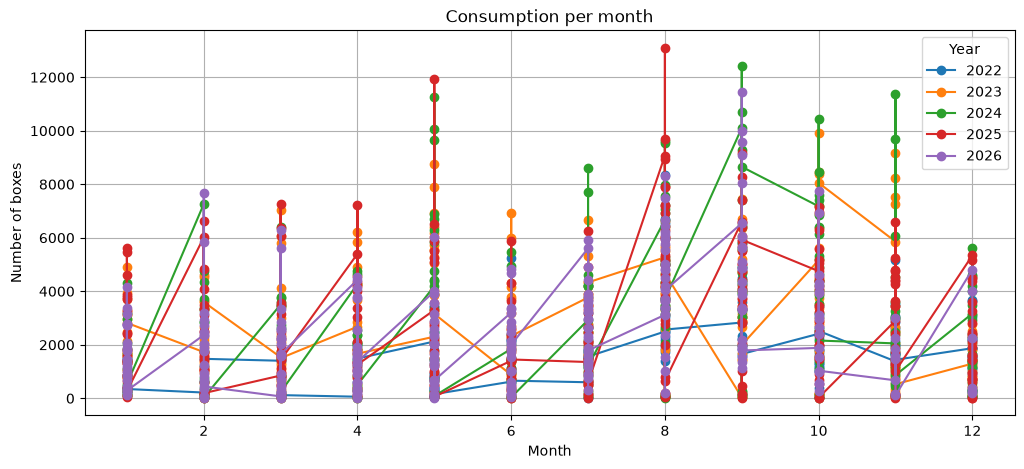

In [26]:
df_grouped = df.groupby("year")
plt.figure(figsize=(12,5))
for label, df_ in df_grouped:
    plt.plot(df_["month"], df_["daily_paper"], marker='o', label=label)
plt.title('Consumption per month')
plt.xlabel('Month')
plt.ylabel('Number of boxes')
plt.legend(title='Year')
plt.grid(True)
plt.show()

<Axes: >

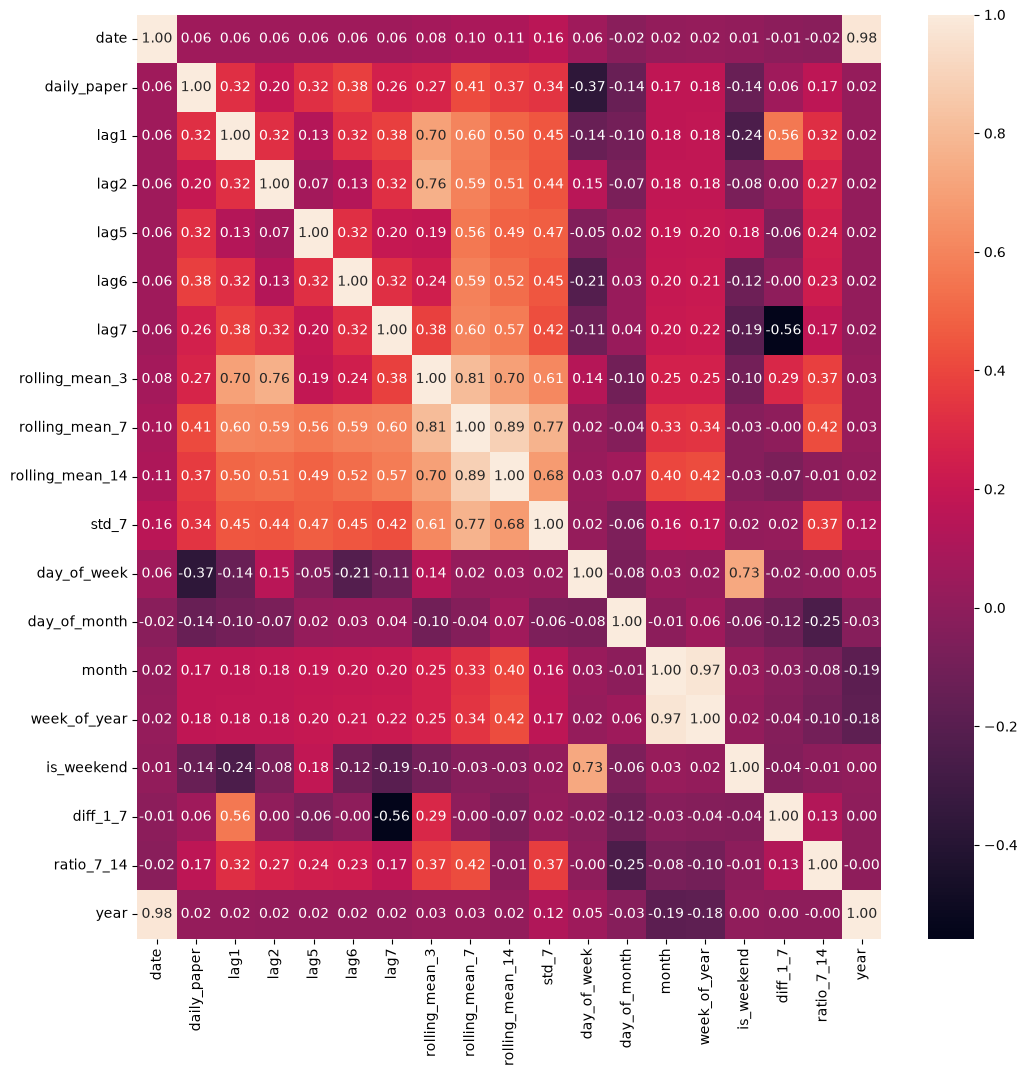

In [27]:
# Correlation matrix
corr_matrix = df.corr()
plt.figure(figsize=(12,12))
sns.heatmap(corr_matrix, annot=True, fmt=".2f")

## Functions

In [35]:
def normalize_split_data(df, train_size=0.75, Target="Consumo_mensal"):
    '''Normalizes the data and splits it into training and testing sets.
    Arguments:
    df -- DataFrame containing the data to be normalized and split
    train_size -- Proportion of the data to be used for training (default: 0.75)
    Target -- Name of the target column (default: "Consumo_mensal")
    '''
    scaler = MinMaxScaler()
    train_data = df.iloc[:int(len(df)*train_size)]
    test_data = df.iloc[int(len(df)*train_size):]
    columns = df.drop(Target, axis=1).columns
    train_data[columns] = scaler.fit_transform(train_data.drop(Target, axis=1))
    test_data[columns] = scaler.transform(test_data.drop(Target, axis=1))

    return train_data, test_data, scaler

def train_model(X_train, y_train, X_test, y_test, model):
    '''Trains a model and returns the model, residuals, and metrics.
    Arguments:
    X_train -- Training features
    y_train -- Training target
    X_test -- Testing features
    y_test -- Testing target
    model -- Model to be trained
    '''
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mape = mean_absolute_percentage_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    results = pd.DataFrame({
        "MAE": [mae],
        "MAPE": [mape],
        "MSE": [mse],
        "R2": [r2]
    })
    residues = y_test.values.flatten() - predictions

    return model, residues, results


## Feature selection

In [43]:
# Preparing the data for modeling
df = df.bfill()
train_size = int(len(df) * 0.75)
X_train = df.drop(columns="Consumo_mensal").iloc[:train_size]
y_train = df["Consumo_mensal"].iloc[:train_size]

# importance threshold
importance_threshold = 0.01

# Feature selection using Random Forest Regressor
rf = RandomForestRegressor(n_jobs=-1, random_state=65)
rf.fit(X_train, y_train)
df_rf_selected = pd.DataFrame({'Feature': X_train.columns, 'Importance': rf.feature_importances_}) # Feature importance from Random Forest
df_rf_selected = df_rf_selected.sort_values(by='Importance', ascending=False).reset_index(drop=True)
df_rf_selected['acumulative_importance'] = df_rf_selected['Importance'].cumsum()
et_features = df_rf_selected[df_rf_selected['acumulative_importance'] >= importance_threshold]['Feature'].tolist() # Select features that contribute to the specified importance threshold
print(X_train.columns)
print(f"Selected features based on Random Forest importance threshold of {importance_threshold}:")
for feature in et_features:
    print(f"- {feature}")

Index(['Ano', 'Mês', 'Estoque_inicial', 'Compras', 'Month_sen', 'Month_cos',
       'Lag1', 'Lag2', 'Lag8', 'Lag10', 'Moving_Average_3_Months',
       'Moving_Average_6_Months', 'Moving_Average_12_Months', 'Trend'],
      dtype='str')
Selected features based on Random Forest importance threshold of 0.01:
- Month_sen
- Moving_Average_3_Months
- Trend
- Lag1
- Lag8
- Mês
- Month_cos
- Moving_Average_12_Months
- Estoque_inicial
- Moving_Average_6_Months
- Lag2
- Lag10
- Compras
- Ano


## Train Models

In [37]:
# Preparing data
df_ = df.drop(columns=["Ano", "Mês", "Compras"]).dropna()
train, test, scaler = normalize_split_data(df=df_)

# Training the XGBoost model
xgb_model, xgb_residues, xgb_results = train_model(
    train.drop("Consumo_mensal", axis=1),
    train[["Consumo_mensal"]],
    test.drop("Consumo_mensal", axis=1),
    test[["Consumo_mensal"]],
    XGBRegressor())

# Training the LightGBM model
lgbm_model, lgbm_residues, lgbm_results = train_model(
    train.drop("Consumo_mensal", axis=1),
        train[["Consumo_mensal"]],
        test.drop("Consumo_mensal", axis=1),
        test[["Consumo_mensal"]],
        LGBMRegressor())

# Training the Random Forest model
rf_model, rf_residues, rf_results = train_model(
    train.drop("Consumo_mensal", axis=1),
        train[["Consumo_mensal"]],
        test.drop("Consumo_mensal", axis=1),
        test[["Consumo_mensal"]],
        RandomForestRegressor())

# Training the Extra Trees model
et_model, et_residues, et_results = train_model(
    train.drop("Consumo_mensal", axis=1),
        train[["Consumo_mensal"]],
        test.drop("Consumo_mensal", axis=1),
        test[["Consumo_mensal"]],
        ExtraTreesRegressor())

# Aggregating the results of all models
results = pd.concat([xgb_results, lgbm_results, rf_results, et_results], axis=0)
results.index = ["XGBoost", "LightGBM", "Random Forest", "Extra Trees"]

[LightGBM] [Warning] There are no meaningful features which satisfy the provided configuration. Decreasing Dataset parameters min_data_in_bin or min_data_in_leaf and re-constructing Dataset might resolve this warning.
[LightGBM] [Info] Total Bins 0
[LightGBM] [Info] Number of data points in the train set: 33, number of used features: 0
[LightGBM] [Info] Start training from score 44.666667
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the spl

c:\Users\9000639\Documents\CQ_SerieTemporal\temporal-series-analysis\.venv\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\9000639\Documents\CQ_SerieTemporal\temporal-series-analysis\.venv\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


In [38]:
results.sort_values(by="MSE", ascending=True)

,MAE,MAPE,MSE,R2
Extra Trees,5.595000,0.138126,64.117500,0.880839
Random Forest,8.192500,0.224232,109.855425,0.795837
XGBoost,9.011799,0.257709,119.237144,0.778401
LightGBM,19.027778,0.501730,538.138889,-0.000116


In [39]:
test

,Estoque_inicial,Consumo_mensal,Month_sen,Month_cos,Lag1,Lag2,Lag8,Lag10,Moving_Average_3_Months,Moving_Average_6_Months,Moving_Average_12_Months,Trend
33,-0.057762,72.0,0.066987,0.750000,0.828947,0.552632,0.131579,0.289474,0.913295,0.652174,0.411765,0.607848
34,0.187726,45.0,0.250000,0.933013,0.723684,0.828947,0.171053,0.157895,0.832370,0.681159,0.378151,0.310149
35,0.469314,32.0,0.500000,1.000000,0.368421,0.723684,0.184211,0.131579,0.554913,0.713768,0.319328,0.130589
36,0.353791,31.0,0.750000,0.933013,0.197368,0.368421,0.263158,0.171053,0.317919,0.663043,0.336134,0.186815
37,0.241877,18.0,0.933013,0.750000,0.184211,0.197368,0.078947,0.184211,0.161850,0.514493,0.260504,0.355039
38,0.176895,22.0,1.000000,0.500000,0.013158,0.184211,0.368421,0.263158,0.104046,0.304348,0.193277,0.101628
39,0.638989,32.0,0.933013,0.250000,0.065789,0.013158,0.552632,0.078947,0.109827,0.159420,0.201681,0.520543
40,0.523466,28.0,0.750000,0.066987,0.197368,0.065789,0.828947,0.368421,0.167630,0.097826,0.126050,0.672237
41,0.422383,34.0,0.500000,0.000000,0.144737,0.197368,0.723684,0.552632,0.236994,0.105072,0.218487,0.293825
42,0.516245,45.0,0.250000,0.066987,0.223684,0.144737,0.368421,0.828947,0.312139,0.155797,0.218487,0.515360


In [40]:
sep = [40, 0.0821540081187317, 0.996619646078697, 88, 45, 31, 45, 55.6666667, 41.5, 43.91666667, 0.95555555556]
oct = [184, 0.091258082081854, 0.995827275412127, 86, 88, 18, 32, 73, 52.1666667, 44.4166666667, -0.022727272727272727]

In [41]:
new_data = oct

In [42]:
new_data_scaled = scaler.transform([new_data])
result_model = xgb_model.predict(new_data_scaled)
print(f"Predicted consumption for the new data: {result_model[0]:.2f}")

Predicted consumption for the new data: 50.52


c:\Users\9000639\Documents\CQ_SerieTemporal\temporal-series-analysis\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
